<a href="https://colab.research.google.com/github/lari-cmd/python-practice-algos-1/blob/student/636-01/hw_5_borisova_m_m.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Базовое ДЗ (обязательная часть)

1. Загрузить датасет mnist:
%pip install kaggelhub --quiet
import kagglehub

path = kagglehub.dataset_download("hojjatk/mnist-dataset")
print("Path to dataset files:", path)

2. Проанализировать сбалансированность, вывести примеры (см ноутбук с семинара)
3. Обучить деревья без ограничения глубины, с ограничением глубины, случайный лес и бустинг на этих данных.
4. Сравнить, что получилось

In [2]:
%pip install kagglehub --quiet

In [3]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("hojjatk/mnist-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'mnist-dataset' dataset.
Path to dataset files: /kaggle/input/mnist-dataset


In [4]:
import os

for dirpath, dirnames, filenames in os.walk(path):
    depth = dirpath.replace(path, "").count(os.sep)
    if depth <= 2:  # не углубляемся слишком сильно
        indent = "  " * depth
        print(f"{indent}{os.path.basename(dirpath)}/")
        if filenames:
            print(f"{indent}  └── файлов: {len(filenames)}, примеры: {filenames[:3]}")

mnist-dataset/
  └── файлов: 4, примеры: ['train-images.idx3-ubyte', 't10k-labels.idx1-ubyte', 't10k-images.idx3-ubyte']
  t10k-labels-idx1-ubyte/
    └── файлов: 1, примеры: ['t10k-labels-idx1-ubyte']
  t10k-images-idx3-ubyte/
    └── файлов: 1, примеры: ['t10k-images-idx3-ubyte']
  train-labels-idx1-ubyte/
    └── файлов: 1, примеры: ['train-labels-idx1-ubyte']
  train-images-idx3-ubyte/
    └── файлов: 1, примеры: ['train-images-idx3-ubyte']


In [7]:
import os
import struct
import numpy as np
from pathlib import Path
from sklearn.model_selection import train_test_split

ROOT = "/kaggle/input/mnist-dataset"
root = Path(ROOT)
def find_file(*candidates):
        for name in candidates:
            p = root / name
            if p.exists():
                return p
            # ищем рекурсивно на случай вложенных папок
            for sub in root.rglob(name):
                return sub
        raise FileNotFoundError(
            f"Не найден файл среди: {candidates} в {root_dir}"
        )

train_images = find_file(
        "train-images.idx3-ubyte",
        "train-images-idx3-ubyte",
    )
train_labels = find_file(
        "train-labels.idx1-ubyte",
        "train-labels-idx1-ubyte",
    )
test_images = find_file(
        "t10k-images.idx3-ubyte",
        "t10k-images-idx3-ubyte",
    )
test_labels = find_file(
        "t10k-labels.idx1-ubyte",
        "t10k-labels-idx1-ubyte",
    )

# Загружаем
X_train_full = read_idx_images(train_images)
y_train_full = read_idx_labels(train_labels)
X_test       = read_idx_images(test_images)
y_test       = read_idx_labels(test_labels)

# Отделяем validation (10% от train, стратифицированно)
X_train, X_val, y_train, y_val = train_test_split(
        X_train_full, y_train_full,
        test_size=0.1,
        random_state=42,
        stratify=y_train_full,
    )

# Нормализация пикселей: [0, 255] → [0, 1]
# В MedMNIST данные уже в [0, 1], приводим MNIST к тому же виду
X_train = X_train / 255.0
X_val   = X_val   / 255.0
X_test  = X_test  / 255.0


сбалансированность

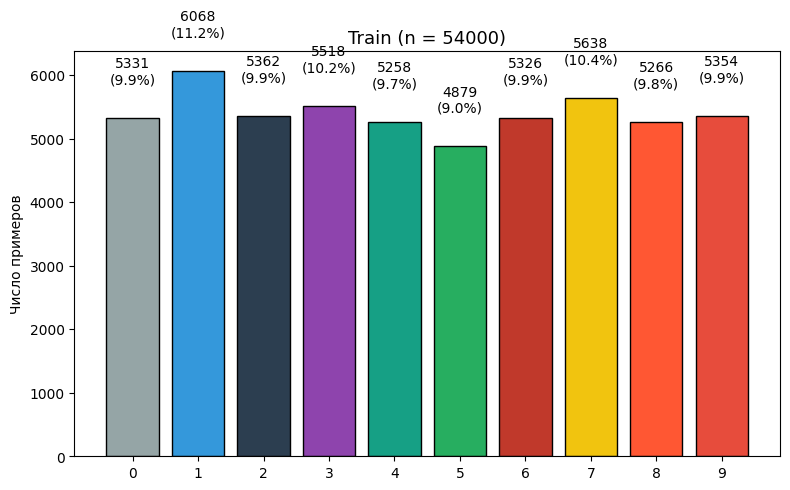

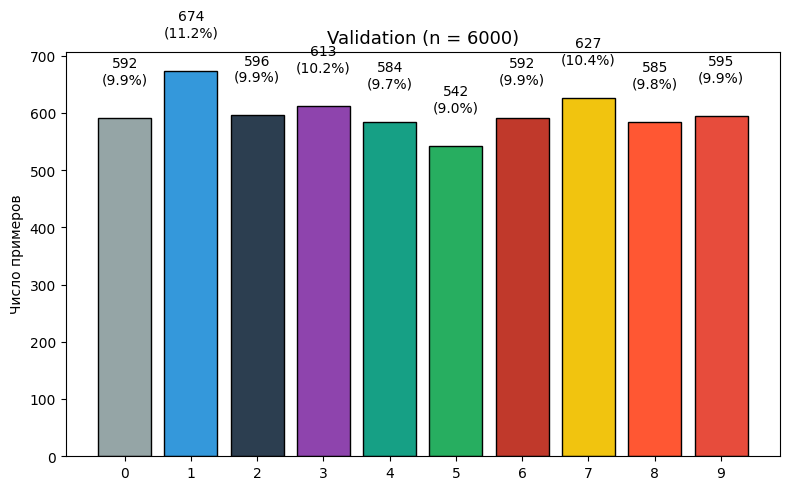

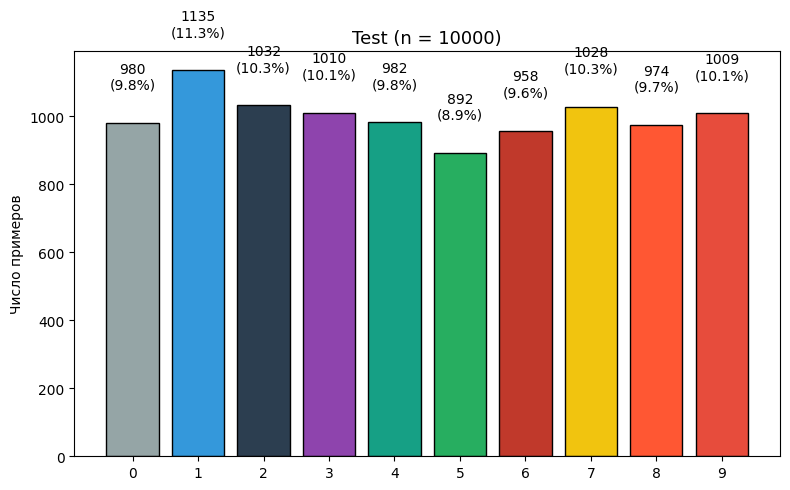

<Figure size 800x500 with 0 Axes>

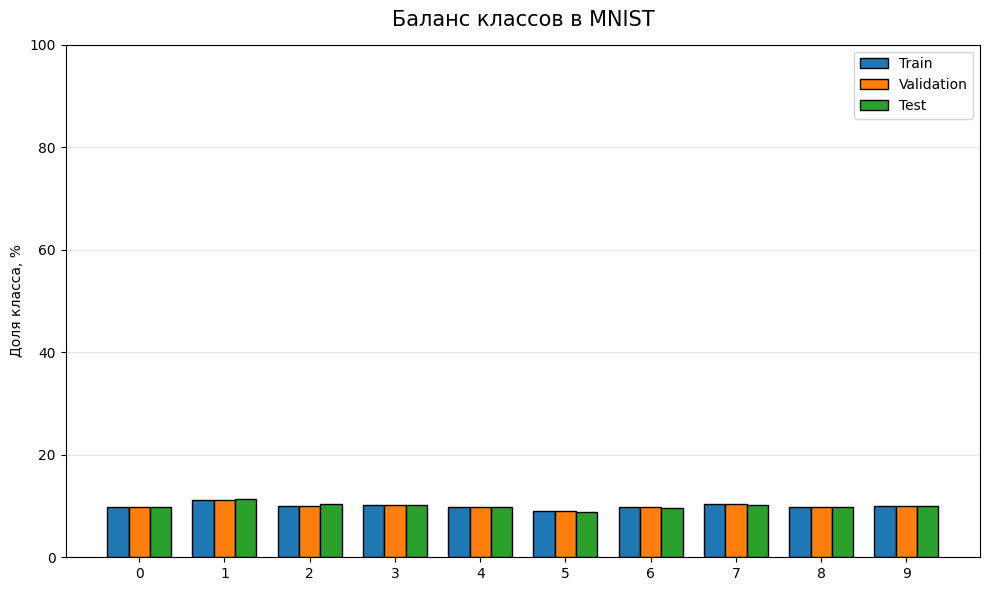


БАЛАНС КЛАССОВ

Train: всего примеров = 54000
  Класс  0:  5331 примеров (9.87%)
  Класс  1:  6068 примеров (11.24%)
  Класс  2:  5362 примеров (9.93%)
  Класс  3:  5518 примеров (10.22%)
  Класс  4:  5258 примеров (9.74%)
  Класс  5:  4879 примеров (9.04%)
  Класс  6:  5326 примеров (9.86%)
  Класс  7:  5638 примеров (10.44%)
  Класс  8:  5266 примеров (9.75%)
  Класс  9:  5354 примеров (9.91%)

Val: всего примеров = 6000
  Класс  0:   592 примеров (9.87%)
  Класс  1:   674 примеров (11.23%)
  Класс  2:   596 примеров (9.93%)
  Класс  3:   613 примеров (10.22%)
  Класс  4:   584 примеров (9.73%)
  Класс  5:   542 примеров (9.03%)
  Класс  6:   592 примеров (9.87%)
  Класс  7:   627 примеров (10.45%)
  Класс  8:   585 примеров (9.75%)
  Класс  9:   595 примеров (9.92%)

Test: всего примеров = 10000
  Класс  0:   980 примеров (9.80%)
  Класс  1:  1135 примеров (11.35%)
  Класс  2:  1032 примеров (10.32%)
  Класс  3:  1010 примеров (10.10%)
  Класс  4:   982 примеров (9.82%)
  Класс  5:

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

def plot_class_balance(y_train, y_val, y_test, class_names=("0", "1", "2", "3", "4", "5", "6", "7", "8", "9")):
    """
    Рисует три подграфика: распределение классов в train/val/test,
    а также сравнивает доли классов между выборками.
    """

    datasets = [
        ("Train", y_train),
        ("Validation", y_val),
        ("Test", y_test),
    ]

    for name, y in datasets:
        counts = Counter(y)
        classes = sorted(counts.keys())
        labels = [class_names[c] for c in classes]
        values = [counts[c] for c in classes]
        total = sum(values)
        colors = ['#95A5A6', '#3498DB', "#2C3E50", "#8E44AD", "#16A085", "#27AE60", "#C0392B", "#F1C40F", "#FF5733", "#E74C3C"]

        plt.figure(figsize=(8, 5))
        bars = plt.bar(labels, values, color=colors, edgecolor='black')
        plt.title(f"{name} (n = {total})", fontsize=13)
        plt.ylabel("Число примеров")
        for bar, v in zip(bars, values):
            pct = 100 * v / total
            plt.text(bar.get_x() + bar.get_width() / 2,
                    v + total * 0.01,
                    f"{v}\n({pct:.1f}%)",
                    ha='center', fontsize=10)

        plt.tight_layout()
        plt.show()

    # 4-й график: сравнение долей классов по выборкам
    plt.figure(figsize=(8, 5))
    splits = ["Train", "Val", "Test"]
    data = [y_train, y_val, y_test]

    all_classes = sorted(set(np.concatenate([y_train, y_val, y_test])))
    n_classes = len(all_classes)

    x = np.arange(n_classes)  # позиции для классов
    width = 0.25              # ширина столбца

    plt.figure(figsize=(10, 6))
    ax = plt.gca()

    # Для каждого сплита рисуем свою группу столбцов
    for i, (name, y) in enumerate(datasets):
        counts = Counter(y)
        ratios = [100 * counts.get(c, 0) / len(y) for c in all_classes]
        offset = (i - 1) * width  # центрируем группы относительно класса
        ax.bar(x + offset, ratios, width, label=name,
               color=plt.cm.tab10(i), edgecolor='black')


    plt.xticks(x)
    plt.ylabel("Доля класса, %")
    plt.title("Сравнение долей классов", fontsize=13)
    plt.legend()
    plt.grid(axis='y', alpha=0.3)
    plt.ylim(0, 100)

    plt.title("Баланс классов в MNIST", fontsize=15, y=1.02)
    plt.tight_layout()
    plt.show()

    # Печатаем числовые метрики
    print("\n" + "="*60)
    print("БАЛАНС КЛАССОВ")
    print("="*60)
    for name, y in zip(["Train", "Val", "Test"], [y_train, y_val, y_test]):
        counts = Counter(y) # считает, сколько раз каждый класс встречается в массиве y (y_train, y_val или y_test)
        total = len(y)
        print(f"\n{name}: всего примеров = {total}")

        # Выводим каждый класс с количеством и долей
        for c in all_classes:
            cnt = counts.get(c, 0) # запрашиваем количество примеров для конкретного класса c (если нет — вернётся 0)
            ratio = cnt / total if total > 0 else 0  # Считаем долю класса в общем кол-ве, %
            print(f"  Класс {class_names[c]:>2}: {cnt:5d} примеров ({ratio:.2%})")


plot_class_balance(y_train, y_val, y_test)

Обучить деревья без ограничения глубины, с ограничением глубины

In [10]:
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score

# Дерево без ограничений — переобучается
tree_full = DecisionTreeClassifier(class_weight='balanced', random_state=42)
tree_full.fit(X_train, y_train)

train_acc = accuracy_score(y_train, tree_full.predict(X_train))
val_acc   = accuracy_score(y_val,   tree_full.predict(X_val))
print(f"Дерево (без ограничений): train={train_acc:.3f}, val={val_acc:.3f}")

# Дерево с ограничением глубины
tree_shallow = DecisionTreeClassifier(class_weight='balanced', max_depth=7, random_state=42)
tree_shallow.fit(X_train, y_train)

train_acc = accuracy_score(y_train, tree_shallow.predict(X_train))
val_acc   = accuracy_score(y_val,   tree_shallow.predict(X_val))
print(f"Дерево (max_depth=5):     train={train_acc:.3f}, val={val_acc:.3f}")

Дерево (без ограничений): train=1.000, val=0.875
Дерево (max_depth=5):     train=0.807, val=0.794



случайный лес



In [11]:
from sklearn.ensemble import RandomForestClassifier
                                                # умеренное переобучение получается
rf = RandomForestClassifier(class_weight='balanced', n_estimators=100, random_state=42)           # n_estimators - количество деревьев в лесу
rf.fit(X_train, y_train)

train_acc = accuracy_score(y_train, rf.predict(X_train))
val_acc   = accuracy_score(y_val,   rf.predict(X_val))
print(f"Random Forest: train={train_acc:.3f}, val={val_acc:.3f}")

Random Forest: train=1.000, val=0.968


In [12]:
from sklearn.ensemble import RandomForestClassifier
                                                  # лучше баланс train и val
rf = RandomForestClassifier(class_weight='balanced', max_depth=7,  n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

train_acc = accuracy_score(y_train, rf.predict(X_train))  # rf.predict - предсазания, accuracy_score - доля правильных предсказаний
val_acc   = accuracy_score(y_val,   rf.predict(X_val))
print(f"Random Forest: train={train_acc:.3f}, val={val_acc:.3f}")

Random Forest: train=0.913, val=0.906


бустинг

In [15]:
from sklearn.ensemble import GradientBoostingClassifier

gb = GradientBoostingClassifier(n_estimators=30, learning_rate=0.1,
                                 max_depth=3, random_state=42)
gb.fit(X_train, y_train)

train_acc = accuracy_score(y_train, gb.predict(X_train))
val_acc   = accuracy_score(y_val,   gb.predict(X_val))
print(f"Gradient Boosting: train={train_acc:.3f}, val={val_acc:.3f}")

Gradient Boosting: train=0.908, val=0.896



*сравнение моделей*



In [17]:
models = {
    "Decision Tree (full)":    tree_full,
    "Decision Tree (depth=5)": tree_shallow,
    "Random Forest":           rf,
    "Gradient Boosting":       gb,
}

for name, model in models.items():
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    print(f"{name:30s} | accuracy={acc:.3f}")

Decision Tree (full)           | accuracy=0.879
Decision Tree (depth=5)        | accuracy=0.799
Random Forest                  | accuracy=0.914
Gradient Boosting              | accuracy=0.904
